# 10 Klasifikasi Multi-Kelas dengan Imbalance

Tiga kelas atau lebih dengan proporsi timpang. Contoh: sentimen komentar YouTube tentang MBG.

**Peringatan data:** label di dataset ini **hasil keluaran model**, bukan anotasi manusia. Skornya
mengukur seberapa mirip dengan model itu, bukan kebenaran sentimen. Notebook ini tetap berguna
sebagai pola, dan kolom `Confidence Score` dipakai untuk melihat dampak label yang meragukan.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Klasifikasi multi-kelas dengan kelas timpang |
| **Unit prediksi** | Satu komentar mendapat satu kelas sentimen |
| **Metrik** | Macro-F1 |
| **Masalah terbesar** | Kelas timpang dan label bukan buatan manusia: negatif 69,1%, netral 8,4%. Label dataset ini tampaknya keluaran model, jadi skornya mengukur kemiripan dengan model itu. |
| **Data contoh** | 5.000 komentar YouTube MBG |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** semua data latih berlabel, kelasnya tiga atau lebih, dan metriknya macro-F1. Berlaku
untuk sentimen, emosi, stance, atau kategori topik.

**Yang perlu diganti kalau datanya beda:**
- `load_data`, `TEXT_COL`, `LABEL_COL`, `CLASSES`.
- Sel analisis `Confidence Score` di bagian 10 dihapus kalau kolomnya tidak ada.
- Varian emosi berlabel manusia ada di paket offline: `indonlu/dataset/emot_emotion-twitter`.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya TF-IDF, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
HOLDOUT_SHARE = 0.2
TEXT_COL, LABEL_COL, CONF_COL = "Cleaned Comment", "Sentiment", "Confidence Score"
CLASSES = ["negative", "neutral", "positive"]
MIN_GAIN = 0.002  # pengali hanya dipakai kalau skor OOF nested naik lebih dari ini

SETTINGS = {
    "cepat": {"folds": 3, "epochs": 3, "model_runs": [("indobertweet", SEED)]},
    "penuh": {
        "folds": 5,
        "epochs": 4,
        "model_runs": [("indobertweet", SEED), ("indobert", SEED), ("indobertweet", SEED + 1)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'folds': 5, 'epochs': 4, 'model_runs': [('indobertweet', 42), ('indobert', 42), ('indobertweet', 43)]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Metrik, interval noise, dan pencatat hasil.** Metrik diuji dulu pada contoh yang jawabannya
dihitung manual. `record` mencatat skor OOF dan skor holdout untuk tiap pendekatan.

In [6]:
from sklearn.metrics import f1_score  # noqa: E402
from sklearn.model_selection import StratifiedGroupKFold  # noqa: E402


def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


assert abs(macro_f1([0, 0, 1, 1], [0, 1, 1, 1]) - (2 / 3 + 0.8) / 2) < 1e-9


def bootstrap_interval(y_true, y_pred, score_fn=macro_f1, n_boot: int = 300) -> str:
    """Interval 95%. Selisih di dalam interval ini belum tentu perbaikan nyata."""
    rng = np.random.default_rng(SEED)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(y_true), len(y_true))
        scores.append(score_fn(y_true[pick], y_pred[pick]))
    return f"{np.percentile(scores, 2.5):.3f}-{np.percentile(scores, 97.5):.3f}"


def make_folds(target, groups, n_folds: int) -> np.ndarray:
    """StratifiedGroupKFold: duplikat tidak lintas fold, proporsi kelas terjaga."""
    splitter = StratifiedGroupKFold(n_folds, shuffle=True, random_state=SEED)
    folds = np.zeros(len(target), dtype=int)
    for fold, (_, val_idx) in enumerate(splitter.split(np.zeros(len(target)), target, groups)):
        folds[val_idx] = fold
    return folds


results: list[dict] = []


def record(name: str, oof_pred, holdout_pred, score_fn=macro_f1) -> None:
    """Catat skor OOF dan holdout. Holdout hanya untuk laporan, bukan untuk memilih model."""
    results.append(
        {
            "model": name,
            "oof": round(score_fn(y, oof_pred), 4),
            "oof_ci95": bootstrap_interval(y, oof_pred, score_fn),
            "holdout": round(score_fn(y_holdout, holdout_pred), 4),
        }
    )
    print(results[-1])

**Model dengan cross-validation.** `cv_tfidf` adalah baseline word dan char TF-IDF + regresi
logistik, sedangkan `cv_transformer` melatih tiap kombinasi model dan seed di semua fold. Hasilnya
probabilitas OOF dan rata-rata probabilitas holdout.

In [7]:
from scipy.sparse import hstack  # noqa: E402
from sklearn.multiclass import OneVsRestClassifier  # noqa: E402


def cv_tfidf(train_texts, target, holdout_texts, folds, multilabel=False):
    """Baseline TF-IDF. Vektorisasi difit di dalam fold supaya tidak bocor."""
    target = np.asarray(target)
    shape = target.shape[1] if multilabel else int(target.max()) + 1
    oof = np.zeros((len(target), shape))
    holdout = np.zeros((len(holdout_texts), shape))
    train_texts = pd.Series(list(train_texts))
    holdout_series = pd.Series(list(holdout_texts))
    for fold in np.unique(folds):
        fit, val = folds != fold, folds == fold
        word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)
        x_fit = hstack([word.fit_transform(train_texts[fit]), char.fit_transform(train_texts[fit])])
        base = LogisticRegression(C=3.0, max_iter=2000, class_weight="balanced")
        model = OneVsRestClassifier(base) if multilabel else base
        model.fit(x_fit.tocsr(), target[fit])
        for mask_texts, store, where in (
            (train_texts[val], oof, val),
            (holdout_series, holdout, None),
        ):
            x_pred = hstack([word.transform(mask_texts), char.transform(mask_texts)]).tocsr()
            probs = model.predict_proba(x_pred)
            if where is None:
                store += probs / len(np.unique(folds))
            else:
                store[where] = probs
    return oof, holdout


def cv_transformer(
    train_texts,
    target,
    holdout_texts,
    folds,
    model_runs,
    epochs,
    problem="ce",
    balanced=True,
    max_len=128,
):
    """Latih tiap (model, seed) di semua fold, lalu rata-ratakan probabilitasnya."""
    target = np.asarray(target)
    train_texts = np.array(list(train_texts), dtype=object)
    holdout_texts = list(holdout_texts)
    n_out = (
        target.shape[1] if problem == "bce" else (1 if problem == "mse" else int(target.max()) + 1)
    )
    oof = np.zeros((len(target), n_out))
    holdout = np.zeros((len(holdout_texts), n_out))
    n_folds = len(np.unique(folds))
    for model_name, seed in model_runs:
        for fold in range(n_folds):
            fit, val = folds != fold, folds == fold
            weights = None
            if problem == "ce" and balanced:
                weights = len(target[fit]) / (n_out * np.bincount(target[fit], minlength=n_out))
            elif problem == "bce" and balanced:
                positives = np.maximum(target[fit].sum(0), 1)
                weights = np.clip((len(target[fit]) - positives) / positives, 1, 20)
            pred_val, pred_hold = train_predict(
                model_name,
                train_texts[fit].tolist(),
                target[fit],
                [train_texts[val].tolist(), holdout_texts],
                problem=problem,
                num_labels=n_out if problem != "bce" else None,
                class_weights=weights,
                epochs=epochs,
                seed=seed + fold,
                max_len=max_len,
            )
            oof[val] += pred_val.reshape(val.sum(), -1) / len(model_runs)
            holdout += pred_hold.reshape(len(holdout_texts), -1) / (n_folds * len(model_runs))
    return oof, holdout

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [8]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

**Decision layer multi-kelas.** Pengali per kelas dicari untuk memaksimalkan macro-F1. Skor
dilaporkan secara *nested*: pengali untuk tiap fold difit dari fold lain, jadi skornya jujur.

In [9]:
from sklearn.metrics import f1_score as _f1  # noqa: E402


def fit_class_multipliers(probs: np.ndarray, y: np.ndarray, rounds: int = 2) -> np.ndarray:
    """Coordinate ascent untuk pengali kelas yang memaksimalkan macro-F1."""
    multipliers = np.ones(probs.shape[1])
    grid = np.arange(0.4, 2.55, 0.1)
    for _ in range(rounds):
        for cls in range(probs.shape[1]):
            scores = []
            for value in grid:
                trial = multipliers.copy()
                trial[cls] = value
                scores.append(_f1(y, (probs * trial).argmax(1), average="macro", zero_division=0))
            multipliers[cls] = grid[int(np.argmax(scores))]
    return multipliers


def nested_multiplier_predictions(
    probs: np.ndarray, y: np.ndarray, folds: np.ndarray
) -> np.ndarray:
    """Prediksi OOF: tiap fold memakai pengali yang difit dari fold lain."""
    preds = np.zeros(len(y), dtype=int)
    for fold in np.unique(folds):
        fit_mask = folds != fold
        multipliers = fit_class_multipliers(probs[fit_mask], y[fit_mask])
        preds[~fit_mask] = (probs[~fit_mask] * multipliers).argmax(1)
    return preds

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [10]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat data, lalu sisihkan holdout yang hanya dipakai untuk laporan akhir.

In [11]:
from sklearn.model_selection import train_test_split  # noqa: E402


def load_data() -> pd.DataFrame:
    frame = pd.read_csv(find_file("comment_sentiment.csv"))
    frame = frame.dropna(subset=[TEXT_COL, LABEL_COL])
    return frame.sample(n=min(N_ROWS, len(frame)), random_state=SEED).reset_index(drop=True)


data = load_data()
train, holdout = train_test_split(
    data, test_size=HOLDOUT_SHARE, stratify=data[LABEL_COL], random_state=SEED
)
train, holdout = train.reset_index(drop=True), holdout.reset_index(drop=True)
print(f"latih={len(train)} | holdout={len(holdout)}")
text_profile(train[TEXT_COL])

latih=4000 | holdout=1000


baris                4000.0
kosong                  0.0
duplikat_persis_%       0.6
kata_median            17.0
kata_p95               89.0
kata_maks            1485.0
ada_url_%               0.0
ada_emoji_%            13.2
dtype: float64

Distribusi kelas dan sebaran keyakinan label.

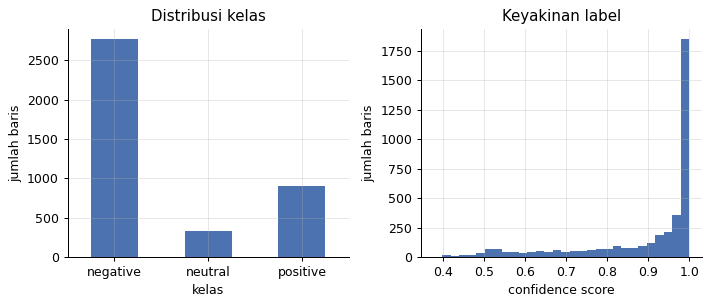

proporsi kelas: {'negative': 0.691, 'positive': 0.225, 'neutral': 0.084}
keyakinan median per kelas: {'negative': 0.988, 'neutral': 0.815, 'positive': 0.913}


In [12]:
fig, axes = plt.subplots(1, 2)
train[LABEL_COL].value_counts().reindex(CLASSES).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title="Distribusi kelas", xlabel="kelas", ylabel="jumlah baris")
axes[0].tick_params(axis="x", rotation=0)
train[CONF_COL].plot.hist(bins=30, ax=axes[1], color="#4C72B0")
axes[1].set(title="Keyakinan label", xlabel="confidence score", ylabel="jumlah baris")
plt.tight_layout()
plt.show()
print("proporsi kelas:", train[LABEL_COL].value_counts(normalize=True).round(3).to_dict())
print("keyakinan median per kelas:", train.groupby(LABEL_COL)[CONF_COL].median().round(3).to_dict())

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Netral hanya 8,4% | Pakai macro-F1, bukan akurasi. Tebak mayoritas akurasinya tinggi tapi macro-F1 0,2724 |
| Keyakinan label median netral 0,815, negatif 0,988 | Label netral paling meragukan, jadi laporkan skor per keyakinan |
| Ada komentar berulang | Grup near-duplicate tidak boleh lintas fold |
| Maksimum 1.485 kata | Teks dipotong oleh tokenizer, dan pembersihan tetap ringan |

## 5. Preprocessing

Pembersihan ringan, emoji dan tanda baca dipertahankan. Slang tidak dinormalisasi karena IndoBERTweet
dilatih dari teks informal. Grup near-duplicate dihitung untuk validasi.

In [13]:
class_to_id = {name: i for i, name in enumerate(CLASSES)}
train["clean"] = train[TEXT_COL].map(clean_text)
holdout["clean"] = holdout[TEXT_COL].map(clean_text)
train["group"] = near_duplicate_groups(train["clean"].tolist())
y = train[LABEL_COL].map(class_to_id).to_numpy()
y_holdout = holdout[LABEL_COL].map(class_to_id).to_numpy()
print(f"grup near-duplicate: {train['group'].nunique()} dari {len(train)} baris")

grup near-duplicate: 3962 dari 4000 baris


## 6. Validasi

Skema `StratifiedGroupKFold`, metrik macro-F1. Accuracy tidak dipakai karena tebak mayoritas saja sudah
terlihat tinggi saat kelasnya timpang.

In [14]:
folds = make_folds(y, train["group"], SETTINGS["folds"])
print(pd.crosstab(folds, train[LABEL_COL]))

Sentiment  negative  neutral  positive
row_0                                 
0               553       69       175
1               551       68       184
2               542       76       180
3               548       67       183
4               570       57       177


## 7. Baseline

Tebak mayoritas, lalu TF-IDF + regresi logistik berbobot kelas.

In [15]:
majority = np.bincount(y).argmax()
record("mayoritas", np.full(len(y), majority), np.full(len(y_holdout), majority))
with stage("baseline_tfidf"):
    oof_tfidf, hold_tfidf = cv_tfidf(train["clean"], y, holdout["clean"], folds)
record("tfidf_lr", oof_tfidf.argmax(1), hold_tfidf.argmax(1))

{'model': 'mayoritas', 'oof': 0.2724, 'oof_ci95': '0.270-0.276', 'holdout': 0.2724}


[waktu] baseline_tfidf: 32 detik


{'model': 'tfidf_lr', 'oof': 0.6242, 'oof_ci95': '0.602-0.644', 'holdout': 0.6625}


## 8. Model Utama

Transformer dengan cross-validation dan bobot kelas seimbang di loss. Tanpa bobot kelas, kelas minoritas
cenderung tidak pernah ditebak. Di mode penuh, hasil tiga run dirata-rata.

In [16]:
with stage("transformer"):
    if USE_PRETRAINED:
        oof_main, hold_main = cv_transformer(
            train["clean"], y, holdout["clean"], folds, SETTINGS["model_runs"], SETTINGS["epochs"]
        )
    else:
        oof_main, hold_main = oof_tfidf, hold_tfidf
record("model_utama", oof_main.argmax(1), hold_main.argmax(1))

[waktu] transformer: 1335 detik


{'model': 'model_utama', 'oof': 0.7438, 'oof_ci95': '0.726-0.760', 'holdout': 0.746}


## 9. Post-processing

Pengali per kelas untuk macro-F1. Biasanya ini langkah paling murah dengan dampak paling besar saat
kelasnya timpang. Skor OOF dihitung nested, jadi jujur.

In [17]:
oof_multiplier = nested_multiplier_predictions(oof_main, y, folds)
multipliers = fit_class_multipliers(oof_main, y)
hold_multiplier = (hold_main * multipliers).argmax(1)
record("model_utama_plus_pengali", oof_multiplier, hold_multiplier)

use_multiplier = macro_f1(y, oof_multiplier) > macro_f1(y, oof_main.argmax(1)) + MIN_GAIN
oof_decision = oof_multiplier if use_multiplier else oof_main.argmax(1)
hold_decision = hold_multiplier if use_multiplier else hold_main.argmax(1)
print("pengali:", dict(zip(CLASSES, multipliers.round(2).tolist())), "-> dipakai:", use_multiplier)

{'model': 'model_utama_plus_pengali', 'oof': 0.7493, 'oof_ci95': '0.732-0.768', 'holdout': 0.7485}
pengali: {'negative': 1.5, 'neutral': 1.0, 'positive': 0.9} -> dipakai: True


## 10. Post-analysis

**Tabel perbandingan.**

In [18]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,oof,oof_ci95,holdout
0,mayoritas,0.2724,0.270-0.276,0.2724
1,tfidf_lr,0.6242,0.602-0.644,0.6625
2,model_utama,0.7438,0.726-0.760,0.7460
3,model_utama_plus_pengali,0.7493,0.732-0.768,0.7485


**Confusion matrix OOF.** Lihat kelas minoritas ke mana salahnya.

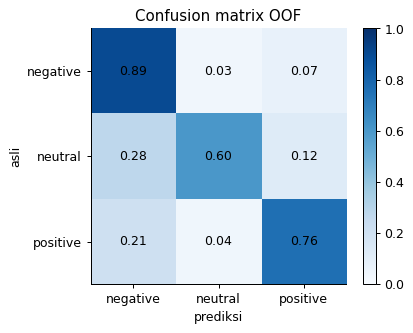

In [19]:
plot_confusion(y, oof_decision, CLASSES, "Confusion matrix OOF")

**Skor menurut keyakinan label.** Kalau skor naik tajam di label yang yakin, sebagian error sebenarnya
berasal dari label yang meragukan, bukan dari model.

In [20]:
buckets = pd.cut(train[CONF_COL], [0, 0.6, 0.8, 0.95, 1.0])
by_confidence = (
    pd.DataFrame({"keyakinan": buckets, "y": y, "pred": oof_decision})
    .groupby("keyakinan", observed=True)
    .apply(
        lambda g: pd.Series({"baris": len(g), "macro_f1": round(macro_f1(g["y"], g["pred"]), 3)}),
        include_groups=False,
    )
)
by_confidence

,baris,macro_f1
keyakinan,,
"(0.0, 0.6]",360.0,0.431
"(0.6, 0.8]",510.0,0.647
"(0.8, 0.95]",825.0,0.744
"(0.95, 1.0]",2305.0,0.881


**Salah prediksi paling yakin.**

In [21]:
errors = train.assign(prediksi=[CLASSES[i] for i in oof_decision], yakin=oof_main.max(1).round(3))
errors = errors[errors[LABEL_COL] != errors["prediksi"]]
errors.sort_values("yakin", ascending=False)[["clean", LABEL_COL, "prediksi", "yakin"]].head(8)

,clean,Sentiment,prediksi,yakin
2584,inti permaslahanya adalah bukan program.semuanya adalah soal tata kelola dan orang yag...,positive,negative,0.990
1604,"ngeloloh kok double2, sudah ada mbg kok bansos masih ada, kayak kehujanan duwit saja. ...",positive,negative,0.989
624,next bahas kopdes prof,negative,neutral,0.988
2643,good job pak. pinter menjelaskan,negative,positive,0.987
2200,ng salah disebut profesor gampang dicerna narasinya dan logik....mantap pak pencerahan...,negative,positive,0.985
3820,gratis kok pake pajak rakyat.dimana gratisnya,positive,negative,0.984
1146,mantapppp pak penjelasannya rinci 🙏 terima kasih,neutral,positive,0.982
3077,"tumben master bahas ginian 😅, tapi saya sangat suka anda obyektif sekali",negative,positive,0.982


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [22]:
submission = pd.DataFrame({"id": holdout.index, "label": [CLASSES[i] for i in hold_decision]})
submission.to_csv(RESULT_DIR / "submission.csv", index=False)
pd.DataFrame(oof_main, columns=CLASSES).assign(fold=folds, y=y).to_csv(
    RESULT_DIR / "oof.csv", index=False
)
run_summary(
    "multi_kelas",
    len(data),
    {r["model"]: {"oof": r["oof"], "holdout": r["holdout"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=multi_kelas mode=penuh n_rows=5000 total_detik=1386 gpu=True
{
 "mayoritas": {
  "oof": 0.2724,
  "holdout": 0.2724
 },
 "tfidf_lr": {
  "oof": 0.6242,
  "holdout": 0.6625
 },
 "model_utama": {
  "oof": 0.7438,
  "holdout": 0.746
 },
 "model_utama_plus_pengali": {
  "oof": 0.7493,
  "holdout": 0.7485
 }
}


**Poin untuk presentasi**

- Macro-F1 OOF naik dari TF-IDF 0,6242 ke model utama 0,7438, lalu 0,7493 dengan pengali kelas. Holdout 0,7485.
- Pengali difit nested dan hanya dipakai kalau naik minimal 0,002.
- Macro-F1 pada keyakinan rendah hanya 0,431, sedangkan pada keyakinan tinggi 0,881. Kesalahan terbesar terkumpul di teks yang memang ambigu.
- Contoh salah seperti `good job pak` berlabel negatif menunjukkan ada noise pada label.